# Analyse Exeperiments Results #

In [1]:
import numpy as np
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from scipy.stats import ttest_ind
from scipy.stats import wilcoxon, ttest_rel
import seaborn as sns
from matplotlib.patches import Ellipse
import ast

import sys
sys.path.append("/home/gavrilev/Thesis/src")

from utils.plot_utils import plot_horizontal_metric, plot_grouped_metrics

In [57]:
def p_to_stars(p_value):
    if np.isnan(p_value):
        return "n.s."
    if p_value < 1e-4:
        return "****"
    if p_value < 1e-3:
        return "***"
    if p_value < 1e-2:
        return "**"
    if p_value < 0.05:
        return "*"
    return "n.s."

def paired_pvalue(x, y, method="wilcoxon"):
    """
    Paired test because all models were evaluated on the same folds.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]
    y = y[mask]

    if len(x) < 2:
        return np.nan

    if method == "ttest":
        return ttest_rel(x, y).pvalue

    try:
        return wilcoxon(x, y, zero_method="wilcox", alternative="two-sided").pvalue
    except ValueError:
        if np.allclose(x, y):
            return 1.0
        return ttest_rel(x, y).pvalue


def safe_parse_per_fold(x):
    if isinstance(x, dict):
        return x
    return ast.literal_eval(x)


def add_sig_bracket(ax, x1, x2, y, h, text, fontsize=10):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        lw=1.2,
        c="black"
    )

    ax.text(
        (x1 + x2) / 2,
        y + h,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize
    )

def get_model_col(df):
    for col in ["model", "Model", "method", "Method"]:
        if col in df.columns:
            return col

    raise ValueError(
        f"Could not find model column. Available columns: {list(df.columns)}"
    )

def get_mean_col(metric, df):
    candidates = [
        f"{metric}_mean",
        f"{metric.upper()}_mean",
        f"{metric}_Mean",
        f"{metric.upper()}_Mean",
        f"{metric}",
    ]

    for col in candidates:
        if col in df.columns:
            return col

    raise ValueError(
        f"Could not find mean column for metric '{metric}'. "
        f"Available columns: {list(df.columns)}"
    )

def get_std_col(metric):
    return f"{metric}_std"

## MultiStructRSA Hyperparameter Search

To optimize the MultiStructRSA architecture, we conducted a progressive hyperparameter search in the following order:

1. **Global hyperparameter search**  
   In this stage, we examined the following hyperparameters: learning rate, weight decay, and dropout, where the same dropout value was used for both the MLPs and the BiDirectionalCrossFusion module.  
   The tested search space was:  
   `{'learning_rate': [1e-5, 2e-5, 5e-5], 'weight_decay': [1e-5, 1e-6], 'dropout': [0.1, 0.2]}`  
   This resulted in `3 × 2 × 2 = 12` experiments.

2. **SMILES module hyperparameter search**  
   In this stage, we evaluated three encoding strategies for the sequence-based features (SimSon and ChemBERTa) and for the expert-based features (Morgan fingerprints and Mordred descriptors).  
   Specifically, we tested:  
   `{'smiles_seq_setting': ['proj', 'shallow', 'deep'], 'smiles_expert_setting': ['proj', 'shallow', 'deep']}`  

   The settings are defined as follows:  
   - `proj`: a simple projection of the input into a lower-dimensional space of size 256, followed by `LayerNorm`.  
   - `shallow`: a shallow MLP with one hidden layer, using the structure `input -> 512 -> 256`. For each layer except the output layer, we applied `LayerNorm -> ReLU -> dropout`.  
   - `deep`: similar to the shallow setting, but with two hidden layers, using the structure `input -> 512 -> 512 -> 256`.  

   In total, this stage included `3 × 3 = 9` experiments.

3. **RNA module hyperparameter search**  
   In this stage, we optimized the BiDirectionalCrossFusion module in two steps.  
   First, we examined the following hyperparameters:  
   `{'d_model': [128, 256], 'ffn_mult': [4, 6], 'bdcf_blocks': [1, 2]}`  

   After selecting the best configuration, we then evaluated the pooling strategies:  
   `{'d_model_ffn_mult_bdcf_blocks': [(128, 4, 1), (128, 4, 2), (256, 4, 1)]'token_pool': ['mean', 'attn'], 'node_pool': ['mean', 'attn']}`  

   In total, the RNA module hyperparameter search included  
   `2 × 2 × 2 + 1 × 2 × 2 = 8 + 4 = 12` experiments.de_pool': ['mean', 'attn']}`

### MultiStruct Global Hyperparameter Search ###

In [3]:
def preprocess_df_hyperparam_plot(path):
    hyperparam_df = pd.read_csv(path)
    exp_description = ['_'.join(exp.split('_')[1:]) for exp in hyperparam_df['exp']]
    hyperparam_df['exp_description'] = exp_description
    return hyperparam_df

In [4]:
GLOBAL_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1304.csv'

In [5]:
glob_hyperparam = pd.read_csv(GLOBAL_HYPERPARAM_PATH)
glob_hyperparam.head()

,exp,family,n_samples,p_mean,p_std,s_mean,s_std,rmse_mean,rmse_std,r2_mean,r2_std,per_fold
0,exp6_lr=5e-5_wd=1e-6_dropout=0.2,all_families,1439,0.78977,0.02473,0.79731,0.01594,0.85948,0.05352,0.62029,0.03814,"{'p': [0.79330844, 0.7528811, 0.7838398, 0.788..."
1,exp7_lr=5e-5_wd=1e-5_dropout=0.1,all_families,1439,0.79081,0.01559,0.79594,0.00872,0.86299,0.03752,0.61758,0.02469,"{'p': [0.7885734, 0.77100027, 0.7782594, 0.802..."
2,exp3_lr=2e-5_wd=1e-5_dropout=0.1,all_families,1439,0.80074,0.02744,0.81101,0.02316,0.83989,0.06033,0.63712,0.04325,"{'p': [0.80817264, 0.7756531, 0.7640726, 0.816..."
3,exp5_lr=5e-5_wd=1e-6_dropout=0.1,all_families,1439,0.80065,0.02480,0.80400,0.01531,0.84149,0.05628,0.63564,0.04123,"{'p': [0.7829648, 0.7724196, 0.79616106, 0.807..."
4,exp4_lr=2e-5_wd=1e-5_dropout=0.2,all_families,1439,0.79549,0.02116,0.80224,0.02012,0.84732,0.05057,0.63109,0.03474,"{'p': [0.81075704, 0.76334345, 0.78807867, 0.7..."


In [6]:
exp_description = ['_'.join(exp.split('_')[1:]) for exp in glob_hyperparam['exp']]
exp_description

['lr=5e-5_wd=1e-6_dropout=0.2',
 'lr=5e-5_wd=1e-5_dropout=0.1',
 'lr=2e-5_wd=1e-5_dropout=0.1',
 'lr=5e-5_wd=1e-6_dropout=0.1',
 'lr=2e-5_wd=1e-5_dropout=0.2',
 'lr=2e-5_wd=1e-6_dropout=0.2',
 'lr=2e-5_wd=1e-6_dropout=0.1',
 'lr=1e-5_wd=1e-6_dropout=0.2',
 'lr=1e-5_wd=1e-5_dropout=0.1',
 'lr=5e-5_wd=1e-5_dropout=0.2',
 'lr=1e-5_wd=1e-5_dropout=0.2',
 'lr=1e-5_wd=1e-6_dropout=0.1']

In [7]:
glob_hyperparam['exp_description'] = exp_description

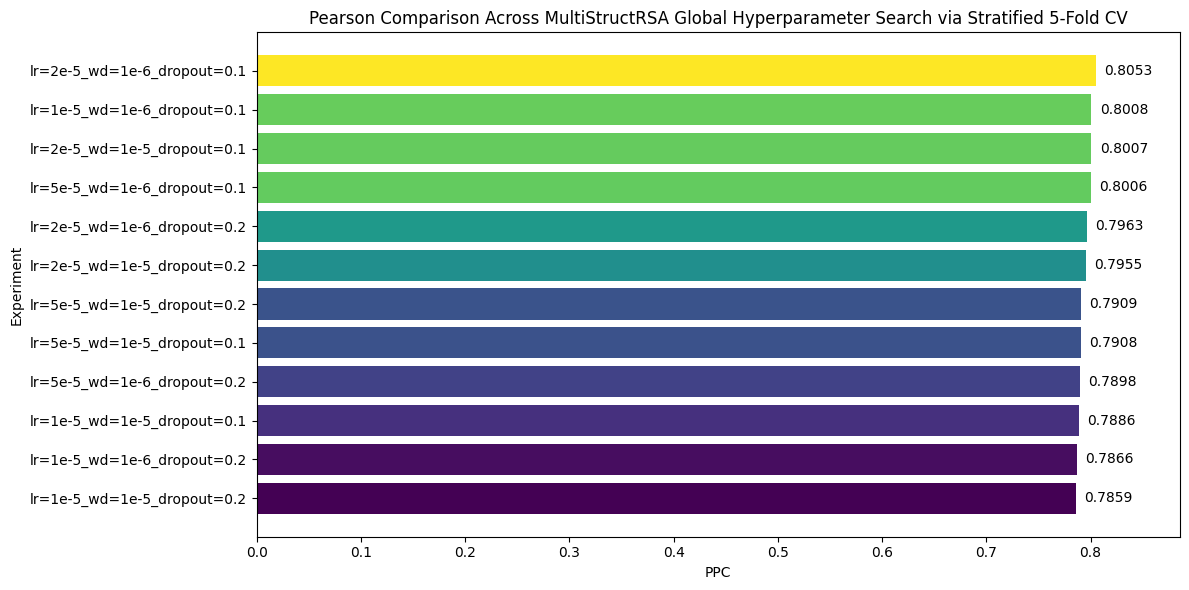

In [8]:
plot_horizontal_metric(
    df=glob_hyperparam,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA Global Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

### RNA Module Hyperparameter Search ###

In [9]:
RNA_BDCF_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1504.csv'
RNA_POOL_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1604.csv'

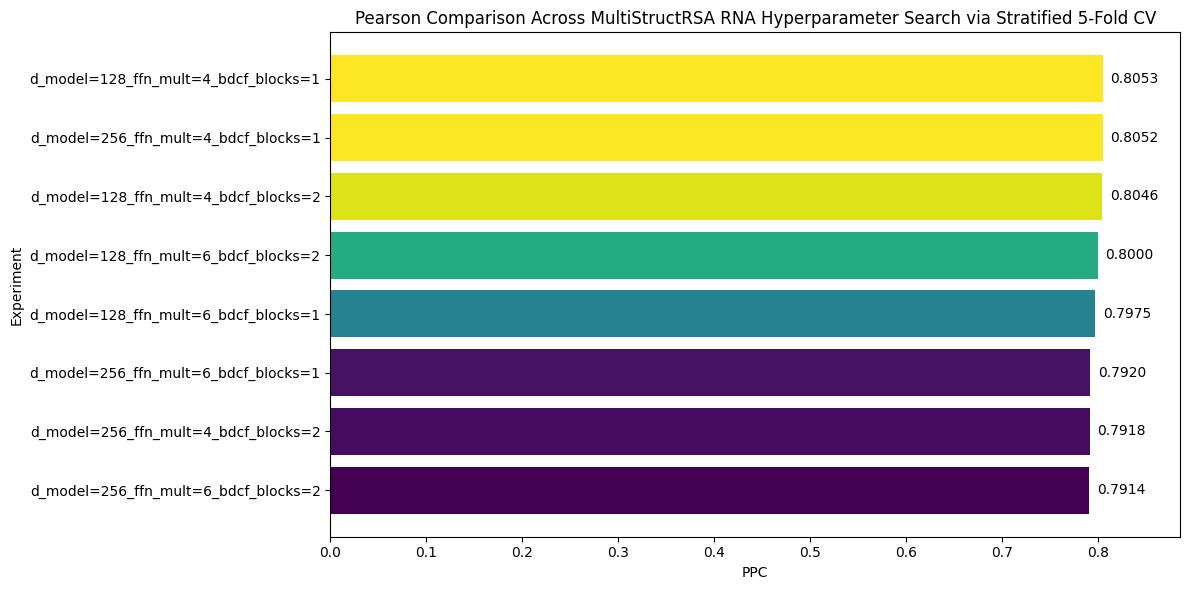

In [10]:
rna_bdcf_hyperparam = preprocess_df_hyperparam_plot(RNA_BDCF_HYPERPARAM_PATH)

plot_horizontal_metric(
    df=rna_bdcf_hyperparam,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

In order to keep the final SMILES encoder dimension at 256, we will continue with the first and third best configurations above, namely (128, 4, 1) and (128, 4, 2), and tune the BiDirectionalCrossFusion pooling mechanisms on the node and token sides.

**Note**: We keep the dimension at 256 because, after pooling the node and token features, we concatenate them along the feature dimension, resulting in an RNA representation of 128 + 128 = 256. If we choose d_model = 256, this would become 256 + 256 = 512. In that case, we would need to perform additional experiments and tuning on the SMILES side as well. Since the differences in performance are not large enough to justify that, we examine two configurations that differ only in the number of BiDirectionalCrossFusion blocks (1 vs. 2).

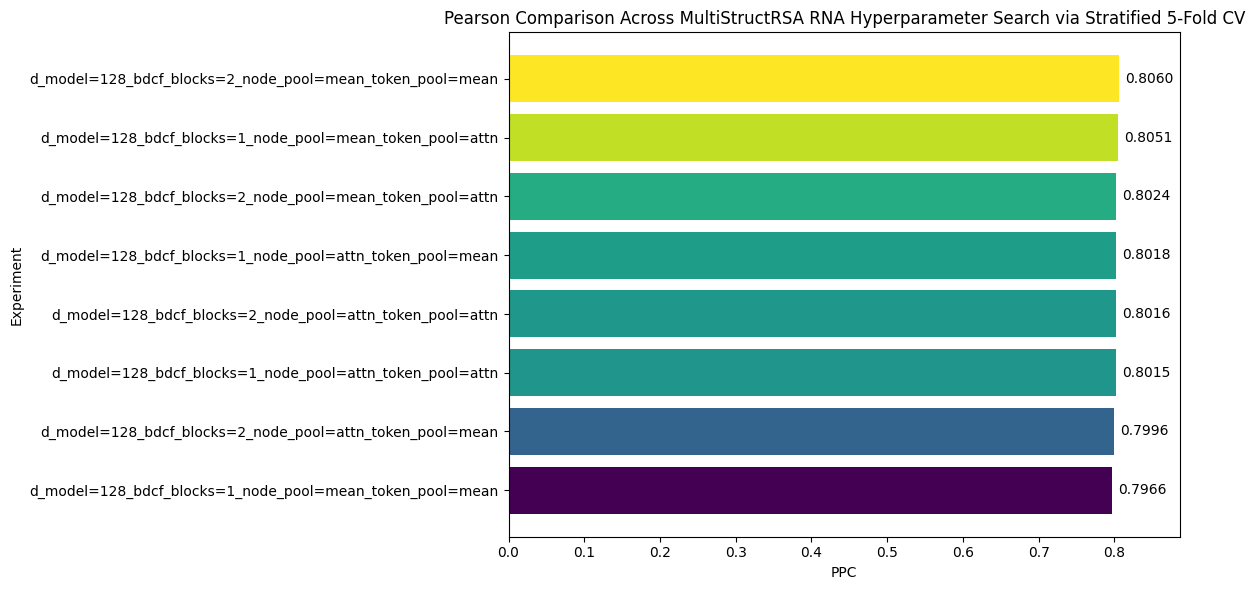

In [11]:
rna_pool_hyperparam_df = preprocess_df_hyperparam_plot(RNA_POOL_HYPERPARAM_PATH)

plot_horizontal_metric(
    df=rna_pool_hyperparam_df,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

we'll keep tuning MultiStructRSA with the configuration that gave us the best results, and then we'll conduct another experiment with the second best con

### Small Molecule Hyperparameter Search ###

In [12]:
SMILES_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1704.csv'

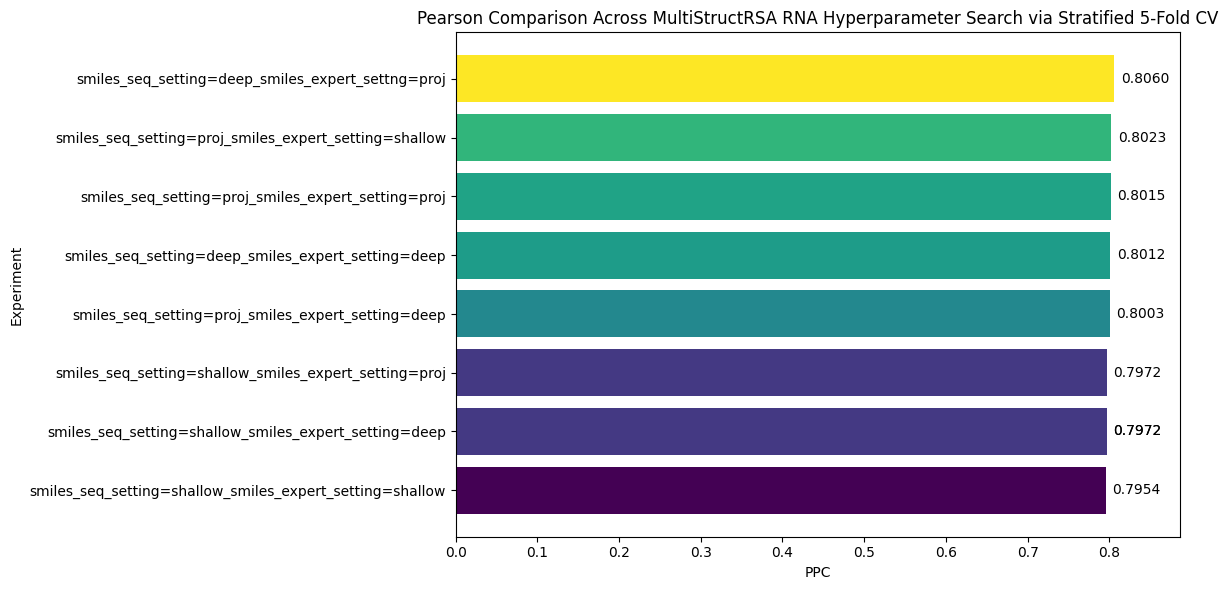

In [13]:
smiles_encoding_hyperparam_df = preprocess_df_hyperparam_plot(SMILES_HYPERPARAM_PATH)

plot_horizontal_metric(
    df=smiles_encoding_hyperparam_df,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

## MultiStructRSA Sensitivity Analysis

After stabilizing the MultiStructRSA architecture through an extensive hyperparameter search, the next step is to perform a sensitivity analysis in order to identify which features in both the RNA and small-molecule modules actually contribute to the model’s performance and which are redundant.  

To this end, we will perform stratified 5-fold cross-validation and remove one feature at a time in each experiment, in order to examine how each feature affects the overall performance of MultiStructRSA.

In [14]:
SENSITIVITY_ANALYSIS1_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1804.csv'

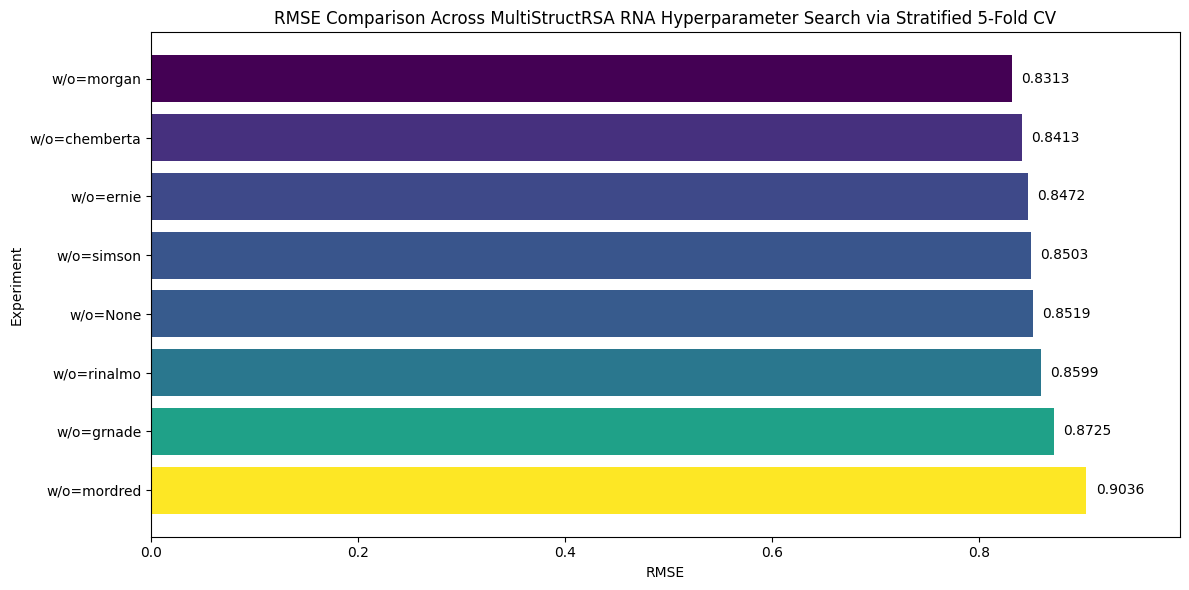

In [15]:
sensitivity_analysis1_df = preprocess_df_hyperparam_plot(SENSITIVITY_ANALYSIS1_PATH)

plot_horizontal_metric(
    df=sensitivity_analysis1_df,
    label_col="exp_description",
    value_col="rmse_mean",
    title="RMSE Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="RMSE",
    ylabel="Experiment",
    sort_ascending=False
)

plt.show()

We observe slightly worse results with the full model compared to the earlier experiments (0.8060 previously versus 0.7953 now). We speculate that this difference may be due to variance in the model, which could be reduced by running more than a single stratified 5-fold cross-validation experiment, for example by performing five runs with different random seeds. 

Moreover, the sensitivity analysis pipeline includes additional parameters and weights in the initialization of MultiStructRSA to make the experiments easier to run under different hyperparameter configurations. Even when some hyperparameters are not used, and their corresponding weights and gradients do not participate in learning or change during training (for example, when the SimSon feature is excluded), their initialization may still affect the randomness and overall weight initialization of the model.

As shown in the figure above, excluding Morgan fingerprints led to the largest improvement in performance. Therefore, we will conduct an additional sensitivity analysis without Morgan fingerprints.

In [16]:
SENSITIVITY_ANALYSIS2_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1904_.csv'

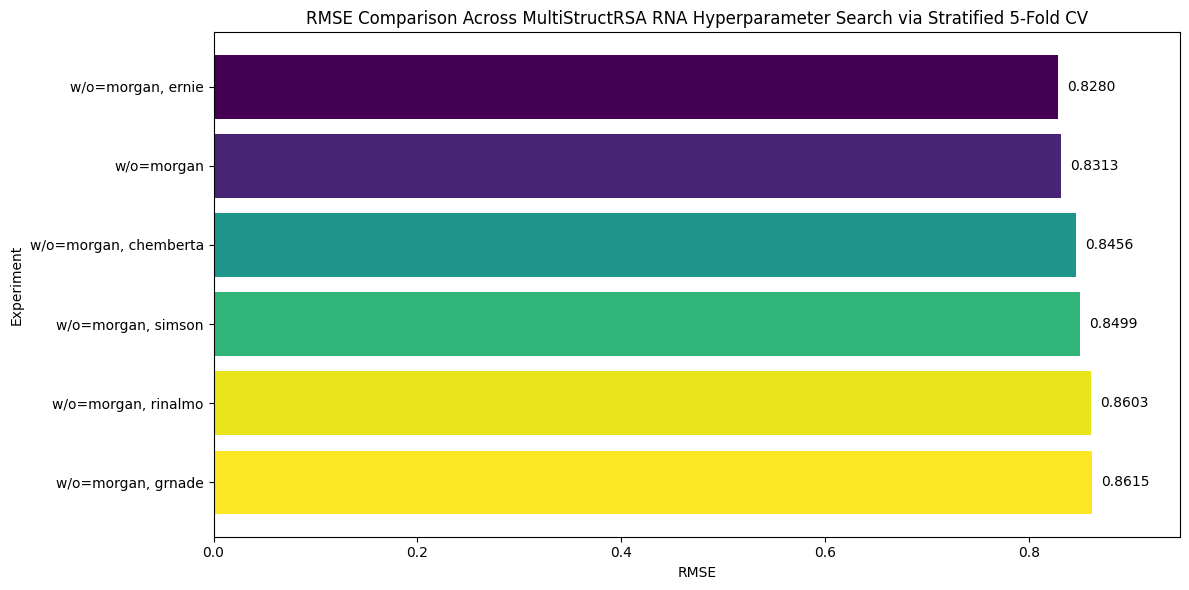

In [17]:
sensitivity_analysis2_df = preprocess_df_hyperparam_plot(SENSITIVITY_ANALYSIS2_PATH)

plot_horizontal_metric(
    df=sensitivity_analysis2_df,
    label_col="exp_description",
    value_col="rmse_mean",
    title="RMSE Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="RMSE",
    ylabel="Experiment",
    sort_ascending=False
)

plt.show()

## MultiStructRSA Ablation Study ##

The following experiments are designed to examine the contribution of predicted RNA 3D structures to RNA–small molecule binding affinity prediction.

The predicted RNA 3D structures were obtained using the AlphaFold3 server. These structures were then processed using the pre-trained gRNAde framework, originally developed for inverse RNA folding. We extracted the pre-trained weights (via Hugging Face) and fine-tuned only the GNN encoder, which takes RNA structural information as input and produces node and edge representations.

In addition, we introduced a cross-modal fusion mechanism named **BiDirectionalCrossFusion**, which integrates RNA graph features with sequence-based language embeddings. This mechanism is based on nucleotide-level cross-attention, where each graph node *i* corresponds to nucleotide *i* in both the structural graph and the sequence embedding space.

Overall, the ablation study evaluates the following model configurations:

1. **w/o 3D structure** – excludes predicted RNA 3D structures (i.e., no AlphaFold3 + gRNAde features)
2. **w/o sequence** – excludes pre-trained RNA language model embeddings (RiNALMo)
3. **w/o fusion** – removes the BiDirectionalCrossFusion module (features are combined via simple concatenation)
4. **MultiStructRSA (frozen)** – full model with frozen gRNAde weights (to assess the contribution of fine-tuning)
5. **MultiStructRSA (full)** – full model with trainable gRNAde encoder

In [18]:
ABLATION_STUDY_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_2004_.csv'

In [19]:
csv_path = ABLATION_STUDY_PATH

In [20]:
ablation_study_df = pd.read_csv(ABLATION_STUDY_PATH)

In [21]:
exp_description = ['_'.join(exp.split('_')[1:]) for exp in ablation_study_df['exp']]
ablation_study_df = ablation_study_df[["rmse_mean", "p_mean", "s_mean"]]
ablation_study_df['exp_description'] = exp_description

In [22]:
ablation_study_df

,rmse_mean,p_mean,s_mean,exp_description
0,0.86631,0.79286,0.79985,
1,0.85103,0.79535,0.80372,
2,0.84056,0.79937,0.80448,
3,0.82798,0.80721,0.80949,
4,0.92334,0.75001,0.75939,


In [23]:
order = ['w/o 3D Struct', 'w/o Seq', 'w/o Fusion', 'MultiStructRSA (frozen)', 'MultiStructRSA']
ablation_study_df['exp_description'] = pd.Categorical(ablation_study_df['exp_description'], categories=order,ordered=True)

ablation_study_df = ablation_study_df.sort_values('exp_description').reset_index(drop=True)
cols = ['exp_description'] + [c for c in ablation_study_df.columns if c != 'exp_description']
ablation_study_df = ablation_study_df[cols]

In [24]:
ablation_study_df

,exp_description,rmse_mean,p_mean,s_mean
0,NaN,0.86631,0.79286,0.79985
1,NaN,0.85103,0.79535,0.80372
2,NaN,0.84056,0.79937,0.80448
3,NaN,0.82798,0.80721,0.80949
4,NaN,0.92334,0.75001,0.75939


/home/gavrilev/Thesis/src/utils/plot_utils.py:267: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")


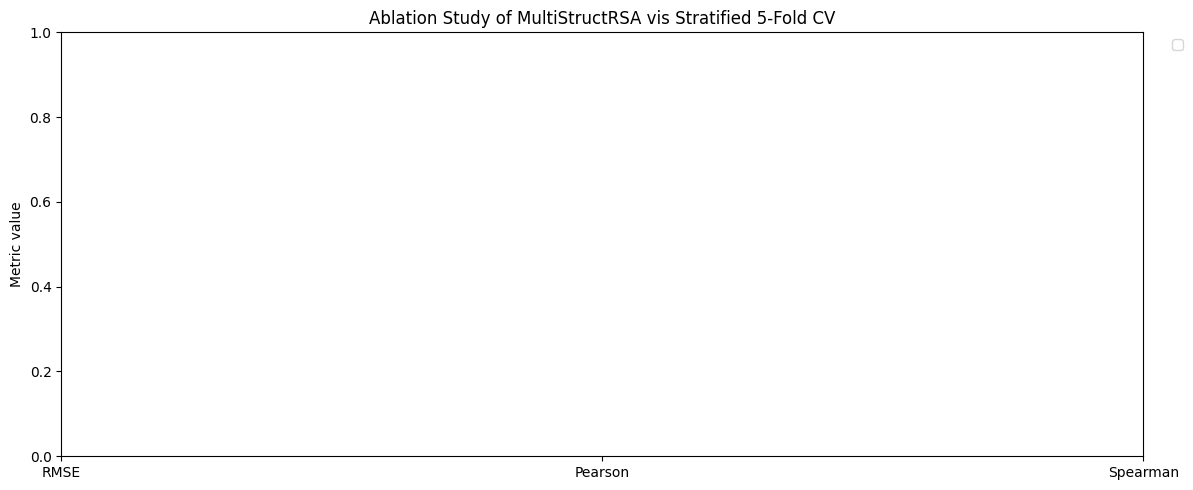

In [25]:
metric_cols = ["rmse_mean", "p_mean", "s_mean"]

metric_labels = {
    "rmse_mean": "RMSE",
    "p_mean": "Pearson",
    "s_mean": "Spearman"
}

exp_order = [
    "w/o 3D Struct",
    "w/o Seq",
    "w/o Fusion",
    "MultiStructRSA (frozen)",
    "MultiStructRSA"
]

plot_grouped_metrics(
    df=ablation_study_df,
    metric_cols=metric_cols,
    exp_col="exp_description",
    exp_order=exp_order,
    metric_labels=metric_labels,
    title="Ablation Study of MultiStructRSA vis Stratified 5-Fold CV",
    lower_is_better=["rmse_mean"]
)

plt.show()

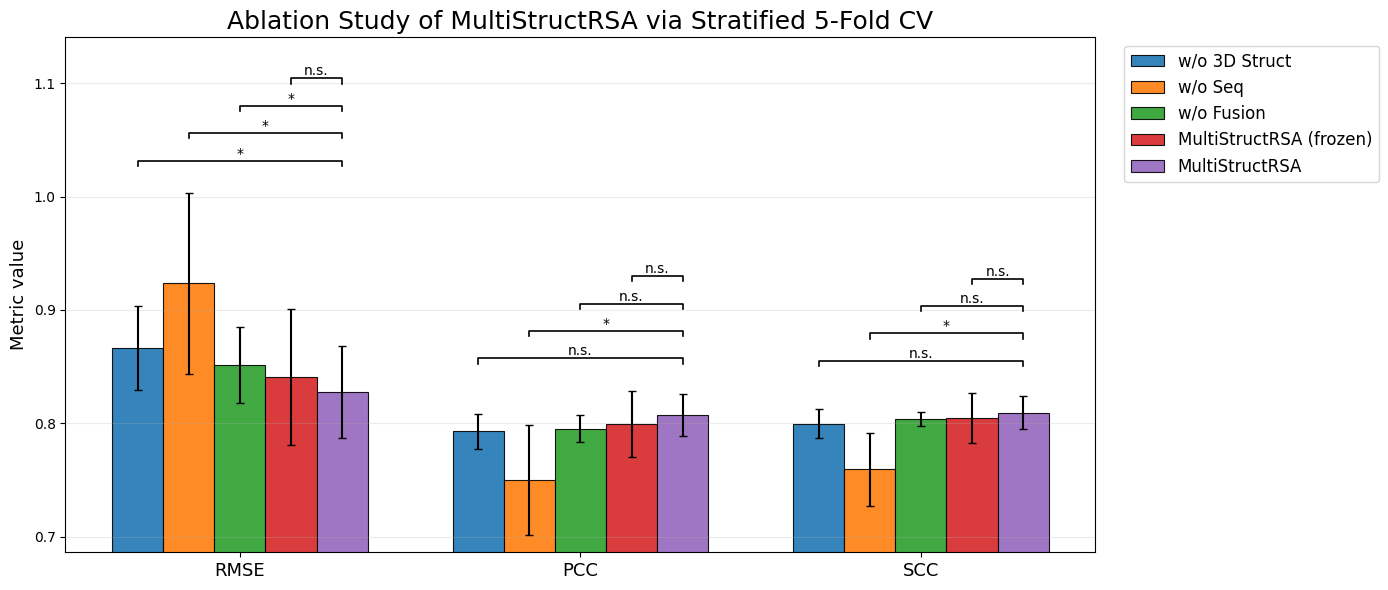

In [26]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, ttest_rel

def plot_ablation_grouped_bars(
    csv_path,
    baseline_model="MultiStructRSA",
    test_method="wilcoxon",
    show_ns=True,
    annotate_bars=True,
    metric_order=("RMSE", "PCC", "SCC"),
    model_order=(
        "w/o 3D Struct",
        "w/o Seq",
        "w/o Fusion",
        "MultiStructRSA (frozen)",
        "MultiStructRSA"
    ),
    figsize=(14, 6),
    save_path=None,

    # controls for significance spacing
    sig_base_gap=0.08,      # space between top bar and first bracket
    sig_line_gap=0.08,      # space between brackets one under/above the other
    sig_bracket_h=0.015,    # bracket vertical height
    sig_fontsize=10
):
    df = pd.read_csv(csv_path)

    if "family" in df.columns:
        df = df[df["family"] == "all_families"].copy()

    df["exp"] = df["exp"].astype(str).str.strip()

    metric_info = {
        "PCC": {
            "mean_col": "p_mean",
            "std_col": "p_std",
            "per_fold_key": "p"
        },
        "SCC": {
            "mean_col": "s_mean",
            "std_col": "s_std",
            "per_fold_key": "s"
        },
        "RMSE": {
            "mean_col": "rmse_mean",
            "std_col": "rmse_std",
            "per_fold_key": "rmse"
        }
    }

    model_order = [m for m in model_order if m in df["exp"].values]

    if baseline_model not in model_order:
        raise ValueError(f"Baseline model '{baseline_model}' was not found in the CSV.")

    n_metrics = len(metric_order)
    n_models = len(model_order)

    x = np.arange(n_metrics)
    bar_width = 0.15

    fig, ax = plt.subplots(figsize=figsize)

    cmap = plt.get_cmap("tab10")
    model_colors = {model: cmap(i % 10) for i, model in enumerate(model_order)}

    bar_centers = {}

    global_top = -np.inf
    global_bottom = np.inf

    # -------------------------
    # draw bars
    # -------------------------
    for i, model_name in enumerate(model_order):
        model_row = df[df["exp"] == model_name]

        if len(model_row) == 0:
            continue

        model_row = model_row.iloc[0]

        means = []
        stds = []

        for metric_name in metric_order:
            means.append(model_row[metric_info[metric_name]["mean_col"]])
            stds.append(model_row[metric_info[metric_name]["std_col"]])

        means = np.array(means, dtype=float)
        stds = np.array(stds, dtype=float)

        offsets = x + (i - (n_models - 1) / 2) * bar_width
        bar_centers[model_name] = offsets

        bars = ax.bar(
            offsets,
            means,
            width=bar_width,
            yerr=stds,
            capsize=3,
            label=model_name,
            color=model_colors[model_name],
            edgecolor="black",
            linewidth=0.8,
            alpha=0.9
        )

        if annotate_bars:
            for bar, val in zip(bars, means):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.01,
                    f"{val:.4f}",
                    ha="center",
                    va="bottom",
                    rotation=90,
                    fontsize=10
                )

        global_top = max(global_top, np.max(means + stds))
        global_bottom = min(global_bottom, np.min(means - stds))

    # -------------------------
    # prepare per-fold values
    # -------------------------
    per_fold_values = {}

    for _, row in df.iterrows():
        model_name = row["exp"]
        per_fold = safe_parse_per_fold(row["per_fold"])
        per_fold_values[model_name] = per_fold

    # -------------------------
    # add significance brackets
    # -------------------------
    y_range = max(global_top - global_bottom, 1e-6)

    bracket_h = sig_bracket_h * y_range
    base_gap = sig_base_gap * y_range
    level_gap = sig_line_gap * y_range

    max_sig_y = global_top

    for metric_idx, metric_name in enumerate(metric_order):
        per_fold_key = metric_info[metric_name]["per_fold_key"]

        base_x = bar_centers[baseline_model][metric_idx]
        level = 0

        metric_tops = []

        for model_name in model_order:
            row = df[df["exp"] == model_name].iloc[0]

            m = row[metric_info[metric_name]["mean_col"]]
            s = row[metric_info[metric_name]["std_col"]]

            metric_tops.append(m + s)

        metric_top = max(metric_tops)

        bracket_base_y = metric_top + base_gap

        for other_model in model_order:
            if other_model == baseline_model:
                continue

            p_value = paired_pvalue(
                per_fold_values[baseline_model][per_fold_key],
                per_fold_values[other_model][per_fold_key],
                method=test_method
            )

            stars = p_to_stars(p_value)

            if (not show_ns) and (stars == "n.s."):
                continue

            other_x = bar_centers[other_model][metric_idx]

            y = bracket_base_y + level * level_gap

            add_sig_bracket(
                ax=ax,
                x1=base_x,
                x2=other_x,
                y=y,
                h=bracket_h,
                text=stars,
                fontsize=sig_fontsize
            )

            max_sig_y = max(max_sig_y, y + bracket_h)
            level += 1

    # -------------------------
    # formatting
    # -------------------------
    ax.set_xticks(x)
    ax.set_xticklabels(metric_order, fontsize=13)

    ax.set_ylabel("Metric value", fontsize=13)
    ax.set_title("Ablation Study of MultiStructRSA via Stratified 5-Fold CV", fontsize=18)

    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=12)
    ax.grid(axis="y", alpha=0.25)

    ax.set_ylim(
        global_bottom - 0.05 * y_range,
        max_sig_y + 0.12 * y_range
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


# =========================
# run
# =========================

plot_ablation_grouped_bars(
    csv_path=csv_path,
    baseline_model="MultiStructRSA",
    test_method="ttest",
    show_ns=True,
    annotate_bars=False,
    metric_order=("RMSE", "PCC", "SCC"),
    model_order=(
        "w/o 3D Struct",
        "w/o Seq",
        "w/o Fusion",
        "MultiStructRSA (frozen)",
        "MultiStructRSA"
    ),
    figsize=(14, 6),
    save_path=None,

    # increase this if you want even more space
    sig_base_gap=0.08,
    sig_line_gap=0.08,
    sig_bracket_h=0.015
)

In [76]:
def plot_ablation_rmse_only(
    csv_path,
    baseline_model="MultiStructRSA",
    test_method="wilcoxon",
    show_ns=True,
    annotate_bars=True,
    model_order=(
        "w/o 3D Struct",
        "w/o Seq",
        "w/o Fusion",
        "MultiStructRSA (frozen)",
        "MultiStructRSA"
    ),
    figsize=(8, 6),
    save_path=None,

    # controls for significance spacing
    sig_base_gap=0.08,
    sig_line_gap=0.08,
    sig_bracket_h=0.015,
    sig_fontsize=14
):
    df = pd.read_csv(csv_path)

    if "family" in df.columns:
        df = df[df["family"] == "all_families"].copy()

    df["exp"] = df["exp"].astype(str).str.strip()

    # keep only models that exist in the file
    model_order = [m for m in model_order if m in df["exp"].values]

    if baseline_model not in model_order:
        raise ValueError(f"Baseline model '{baseline_model}' was not found in the CSV.")

    # --------------------------------------------------
    # sort models by RMSE descending:
    # worst RMSE on the left, best RMSE on the right
    # --------------------------------------------------
    model_order = sorted(
        model_order,
        key=lambda m: float(df[df["exp"] == m]["rmse_mean"].iloc[0]),
        reverse=True
    )

    # -------------------------
    # prepare RMSE values
    # -------------------------
    means = []
    stds = []

    for model_name in model_order:
        row = df[df["exp"] == model_name].iloc[0]

        means.append(row["rmse_mean"])
        stds.append(row["rmse_std"])

    means = np.array(means, dtype=float)
    stds = np.array(stds, dtype=float)

    x = np.arange(len(model_order))

    # -------------------------
    # draw plot
    # -------------------------
    fig, ax = plt.subplots(figsize=figsize)

    cmap = plt.get_cmap("tab10")
    colors = [cmap(i % 10) for i in range(len(model_order))]

    bars = ax.bar(
        x,
        means,
        yerr=stds,
        capsize=4,
        color=colors,
        edgecolor="black",
        linewidth=0.8,
        alpha=0.9
    )

    if annotate_bars:
        for bar, val in zip(bars, means):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f"{val:.4f}",
                ha="center",
                va="bottom",
                fontsize=16,
                rotation=90
            )

    # -------------------------
    # prepare per-fold values
    # -------------------------
    per_fold_values = {}

    for _, row in df.iterrows():
        model_name = row["exp"]
        per_fold = safe_parse_per_fold(row["per_fold"])
        per_fold_values[model_name] = per_fold

    # -------------------------
    # add significance brackets
    # -------------------------
    global_top = np.max(means + stds)
    global_bottom = np.min(means - stds)
    y_range = max(global_top - global_bottom, 1e-6)

    bracket_h = sig_bracket_h * y_range
    base_gap = sig_base_gap * y_range
    level_gap = sig_line_gap * y_range

    baseline_idx = model_order.index(baseline_model)
    baseline_x = x[baseline_idx]

    bracket_base_y = global_top + base_gap
    max_sig_y = global_top

    level = 0

    for other_model in model_order:
        if other_model == baseline_model:
            continue

        other_idx = model_order.index(other_model)
        other_x = x[other_idx]

        p_value = paired_pvalue(
            per_fold_values[baseline_model]["rmse"],
            per_fold_values[other_model]["rmse"],
            method=test_method
        )

        stars = p_to_stars(p_value)

        if (not show_ns) and (stars == "n.s."):
            continue

        y = bracket_base_y + level * level_gap

        add_sig_bracket(
            ax=ax,
            x1=baseline_x,
            x2=other_x,
            y=y,
            h=bracket_h,
            text=stars,
            fontsize=sig_fontsize
        )

        max_sig_y = max(max_sig_y, y + bracket_h)
        level += 1

    # -------------------------
    # formatting
    # -------------------------
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=30, ha="right", fontsize=16)

    ax.set_ylabel("RMSE", fontsize=16)
    ax.set_title("Ablation Study of MultiStructRSA", fontsize=16)
    ax.tick_params(axis="y", labelsize=15)
    ax.grid(axis="y", alpha=0.25)

    ax.set_ylim(
        global_bottom - 0.05 * y_range,
        max_sig_y + 0.12 * y_range
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

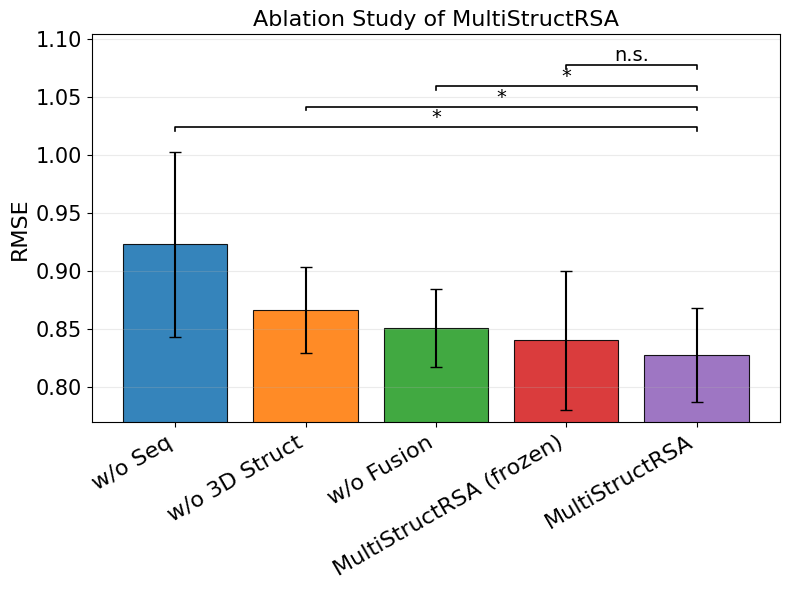

In [77]:
plot_ablation_rmse_only(
    csv_path=csv_path,
    baseline_model="MultiStructRSA",
    test_method="ttest",
    show_ns=True,
    annotate_bars=False,
    figsize=(8, 6),
    save_path=None,
    sig_base_gap=0.08,
    sig_line_gap=0.08,
    sig_bracket_h=0.015
)

## Performance Comparison of Different Models on the R-SIM Data Set Using 5-Fold Cross-Validation ##

In [42]:
# pass

## Cold Start Evaluation ##

### Paired T-test ###

In [43]:
def paired_ttest_from_per_fold(
    comparison_df,
    method_col="method",
    per_fold_col="per_fold",
    method_a="MultiStructRSA",
    method_b="DeepRSMA",
    metrics=None
):
    """
    Calculate paired t-test between two methods using the per_fold column.

    Parameters
    ----------
    comparison_df : pd.DataFrame
        DataFrame with one row per method and a per_fold column.
    method_col : str
        Column name that contains the method names.
    per_fold_col : str
        Column name that contains per-fold dictionaries.
    method_a : str
        First method name.
    method_b : str
        Second method name.
    metrics : dict
        Mapping from displayed metric name to key inside per_fold dict.
        Example: {"Pearson": "p", "Spearman": "s", "RMSE": "rmse"}

    Returns
    -------
    pd.DataFrame
        DataFrame with paired t-test results.
    """

    if metrics is None:
        metrics = {
            "Pearson": "p",
            "Spearman": "s",
            "RMSE": "rmse"
        }

    df = comparison_df.copy()

    # Convert per_fold from string to dict if needed
    df[per_fold_col] = df[per_fold_col].apply( lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

    method_a_per_fold = df.loc[df[method_col] == method_a, per_fold_col].iloc[0]
    method_b_per_fold = df.loc[df[method_col] == method_b, per_fold_col].iloc[0]

    results = []

    for metric_name, key in metrics.items():
        method_a_values = method_a_per_fold[key]
        method_b_values = method_b_per_fold[key]

        t_stat, p_value = ttest_rel(method_a_values, method_b_values)

        method_a_mean = sum(method_a_values) / len(method_a_values)
        method_b_mean = sum(method_b_values) / len(method_b_values)

        results.append({
            "metric": metric_name,
            f"{method_a}_mean": method_a_mean,
            f"{method_b}_mean": method_b_mean,
            "mean_diff": method_a_mean - method_b_mean,
            "t_stat": t_stat,
            "p_value": p_value
        })

    return pd.DataFrame(results)

In [44]:
ttest_results_df = paired_ttest_from_per_fold(
    comparison_df,
    method_a="MultiStructRSA",
    method_b="DeepRSMA"
)

ttest_results_df

NameError: name 'comparison_df' is not defined

In [49]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel


CSV_PATH = "/home/gavrilev/Thesis/src/results/table_results/cold_eval_sota (1) (1).csv"

OUR_MODEL = "MultiStructRSA"
MODEL_ORDER = ["DeepRSMA", "BioLLMNet", "DeepMIF", "MultiStructRSA"]
BASELINE_MODELS = ["DeepRSMA", "BioLLMNet", "DeepMIF"]

COLD_ORDER = ["both", "rna", "mole"]
METRICS = ["p", "s", "rmse"]

METRIC_LABELS = {
    "p": "PCC",
    "s": "SCC",
    "rmse": "RMSE",
}

COLD_LABELS = {
    "both": "Both",
    "rna": "RNA",
    "mole": "Molecule",
}

In [71]:
def add_sig_bar(ax, x1, x2, y, h, text, fontsize=14, linewidth=1.4, text_offset=0.01):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        lw=linewidth,
        c="black"
    )

    ax.text(
        (x1 + x2) / 2,
        y + h + text_offset,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize
    )


def plot_cold_sota_by_metric(
    csv_path=CSV_PATH,
    metrics=METRICS,
    cold_order=COLD_ORDER,
    model_order=MODEL_ORDER,
    baseline_models=BASELINE_MODELS,
    our_model=OUR_MODEL,
    save_path=None,

    sig_base_gap=0.10,
    sig_line_gap=0.16,
    sig_bar_h=0.025,
    sig_fontsize=14,
    sig_linewidth=1.4
):

    df = pd.read_csv(csv_path)

    fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

    bar_width = 0.18
    x = np.arange(len(cold_order))

    for ax, metric in zip(axes, metrics):
        mean_col = get_mean_col(metric, df)
        std_col = get_std_col(metric)

        values_for_ylim = []

        for i, model in enumerate(model_order):
            means = []
            stds = []

            for cold_type in cold_order:
                row = get_row(df, model, cold_type)
                means.append(float(row[mean_col]))
                stds.append(float(row[std_col]))

            offset = (i - (len(model_order) - 1) / 2) * bar_width
            xpos = x + offset

            ax.bar(
                xpos,
                means,
                width=bar_width,
                yerr=stds,
                capsize=3,
                label=model,
                alpha=0.9
            )

            values_for_ylim.extend((np.array(means) + np.array(stds)).tolist())
            values_for_ylim.extend((np.array(means) - np.array(stds)).tolist())

        y_min = min(values_for_ylim)
        y_max = max(values_for_ylim)
        y_range = y_max - y_min

        if y_range == 0:
            y_range = 1.0

        h = sig_bar_h * y_range
        step = sig_line_gap * y_range
        text_offset = 0.025 * y_range
        current_top = y_max

        our_idx = model_order.index(our_model)
        our_offset = (our_idx - (len(model_order) - 1) / 2) * bar_width

        for cold_idx, cold_type in enumerate(cold_order):
            cold_tops = []

            for model in model_order:
                row = get_row(df, model, cold_type)
                cold_tops.append(float(row[mean_col]) + float(row[std_col]))

            base_y = max(cold_tops) + sig_base_gap * y_range
            x_ours = x[cold_idx] + our_offset

            comparisons = []

            for baseline_model in baseline_models:
                baseline_idx = model_order.index(baseline_model)
                baseline_offset = (baseline_idx - (len(model_order) - 1) / 2) * bar_width
                x_other = x[cold_idx] + baseline_offset

                stars, p_value = paired_statistical_significance(
                    df=df,
                    cold_type=cold_type,
                    metric=metric,
                    baseline_model=baseline_model,
                    our_model=our_model,
                    alternative="two-sided"
                )

                comparisons.append({
                    "x_other": x_other,
                    "x_ours": x_ours,
                    "stars": stars,
                    "p_value": p_value,
                    "distance": abs(x_other - x_ours)
                })

            comparisons = sorted(comparisons, key=lambda d: d["distance"])

            for k, comp in enumerate(comparisons):
                y = base_y + k * step

                add_sig_bar(
                    ax=ax,
                    x1=comp["x_other"],
                    x2=comp["x_ours"],
                    y=y,
                    h=h,
                    text=comp["stars"],
                    fontsize=sig_fontsize,
                    linewidth=sig_linewidth,
                    text_offset=text_offset
                )

                current_top = max(current_top, y + h + text_offset)

        ax.set_title(METRIC_LABELS[metric], fontsize=18)
        ax.set_xticks(x)
        ax.set_xticklabels(
            [COLD_LABELS[c] for c in cold_order],
            fontsize=16
        )

        ax.set_xlabel("Cold-start setting", fontsize=16)
        ax.set_ylabel("Score", fontsize=16)

        ax.tick_params(axis="y", labelsize=16)

        ax.set_ylim(
            min(0, y_min - 0.05 * y_range),
            current_top + 0.22 * y_range
        )

        ax.grid(axis="y", alpha=0.25)

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        fontsize=14
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [72]:
res = {'p': [0.4975685110803745, 0.5677356966730667, 0.6114352142577938, 0.3989544352054499, 0.3419780634020062], 's': [0.5731087001606816, 0.548732932520487, 0.5833388236156691, 0.37596850521731384, 0.3640189190753491], 'rmse': [1.165131321783577, 1.023281906711883, 1.1782614942782175, 1.450821090938668, 1.3383917757919115], 'r2': [0.2090807642025566, 0.29050704351650203, 0.3629269956668866, -0.03141662962609537, 0.017430386353647243]}

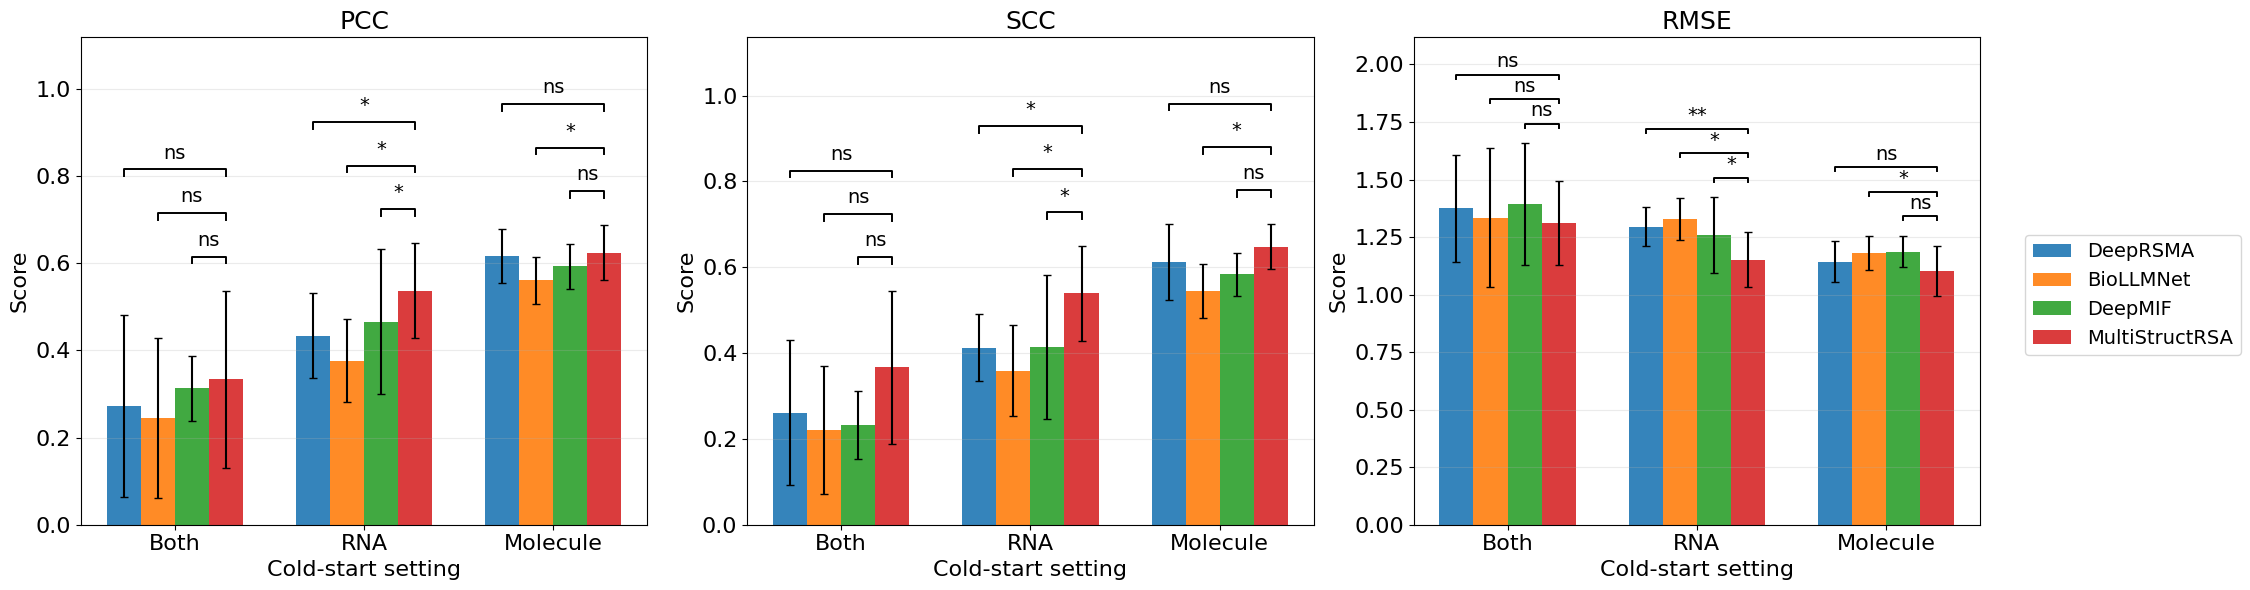

In [73]:
plot_cold_sota_by_metric(
    save_path="/home/gavrilev/Thesis/src/results/cold_eval_sota_by_metric.png"
)

In [59]:
def get_row(df, model, cold_type):
    model_col = get_model_col(df)

    row = df[
        (df[model_col] == model) &
        (df["cold_type"] == cold_type)
    ]

    if len(row) != 1:
        raise ValueError(
            f"Expected 1 row for model={model}, cold_type={cold_type}, "
            f"but found {len(row)}"
        )

    return row.iloc[0]

In [61]:
import ast
from scipy.stats import ttest_rel

def paired_statistical_significance(
    df,
    cold_type,
    metric,
    baseline_model,
    our_model,
    alternative="two-sided"
):
    baseline_row = get_row(df, baseline_model, cold_type)
    our_row = get_row(df, our_model, cold_type)

    baseline_per_fold = ast.literal_eval(baseline_row["per_fold"])
    our_per_fold = ast.literal_eval(our_row["per_fold"])

    baseline_values = baseline_per_fold[metric]
    our_values = our_per_fold[metric]

    _, p_value = ttest_rel(
        our_values,
        baseline_values,
        alternative=alternative
    )

    if p_value < 0.001:
        stars = "***"
    elif p_value < 0.01:
        stars = "**"
    elif p_value < 0.05:
        stars = "*"
    else:
        stars = "ns"

    return stars, p_value